In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("flight_data_ERA5.csv")

print("Dataset shape:", df.shape)

print("\nColumns:")
for col in df.columns:
    print(col)

display(df.head())

Dataset shape: (10642, 38)

Columns:
Used Date
From
To
Airline
Scheduled Departure
SDEP
DEP
SARR
ARR
Departure Delay
Distance
Passenger Load Factor
Airline Rating
Airport Rating
Market Share
OTP Index
Category
Departure_Hour
Scheduled_DateTime
Weather_Cutoff
Past_temperature
Past_windspeedKmph
Past_precipMM
Past_humidity
Past_pressure
Past_cloudcover
Past_weatherDesc
Hourly_Airport_Departures
Airport_Congestion_Index
Is_Weekend
Is_Delayed
temperature_2m
wind_speed_10m
precipitation
relative_humidity_2m
pressure_msl
cloud_cover
weather_code


,Used Date,From,To,Airline,Scheduled Departure,SDEP,DEP,SARR,ARR,Departure Delay,...,Airport_Congestion_Index,Is_Weekend,Is_Delayed,temperature_2m,wind_speed_10m,precipitation,relative_humidity_2m,pressure_msl,cloud_cover,weather_code
0,2019-01-02,BOM,DEL,Vistara,01:10,110,130,320,325,20,...,0.040698,0,1,21.6,10.9,0.0,71,1017.6,64,2
1,2019-01-09,DEL,HYD,Spicejet,22:05,2205,40,25,252,155,...,0.225806,0,1,18.3,7.4,0.0,45,1016.2,0,0
2,2019-01-22,CCU,DEL,SpiceJet,18:30,1830,1838,2055,2106,8,...,1.000000,0,1,28.0,3.3,0.0,40,1015.2,0,0
3,2019-01-23,CCU,DEL,SpiceJet,18:30,1830,1830,2055,2100,0,...,1.000000,0,0,28.9,4.0,0.0,37,1015.0,0,0
4,2019-01-24,CCU,DEL,SpiceJet,18:30,1830,1830,2055,2101,0,...,1.000000,0,0,29.2,4.5,0.0,42,1016.0,0,0


In [2]:
print(df["Is_Delayed"].value_counts())
print(df[["Airline", "From", "To", "Category", "Departure_Hour", "Is_Delayed"]].isnull().sum())

Is_Delayed
0    5471
1    5171
Name: count, dtype: int64
Airline           0
From              0
To                0
Category          0
Departure_Hour    0
Is_Delayed        0
dtype: int64


In [20]:

features = ["Airline", "From", "To", "Departure_Hour"]

X = df[features]

X = pd.get_dummies(
    X,
    columns=["Airline", "From", "To"],
    dtype=int
)

X = X.to_numpy(dtype=float)
y = df["Is_Delayed"].to_numpy()

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (10642, 15)
y shape: (10642,)


In [21]:

# Neural network architecture
input_size = X.shape[1]
hidden_size = 16
output_size = 1

# Initialize weights and biases
np.random.seed(42)

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros(hidden_size)

print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)


W1 shape: (15, 16)
b1 shape: (16,)


In [22]:

# ReLU activation function
def relu(z):
    return np.maximum(0, z)

# Forward pass through hidden layer
Z1 = X @ W1 + b1
A1 = relu(Z1)

print("Z1 shape:", Z1.shape)
print("A1 shape:", A1.shape)

print("\nFirst flight's hidden activations:")
print(A1[0])


Z1 shape: (10642, 16)
A1 shape: (10642, 16)

First flight's hidden activations:
[0.48633193 2.54126184 0.         0.59872876 0.44076263 0.
 0.97029388 0.95843604 0.         0.         0.27279707 0.
 1.82912037 0.         0.         0.        ]


In [23]:

# Initialize output layer weights and bias
W2 = np.random.randn(hidden_size, output_size) * np.sqrt(1 / hidden_size)
b2 = np.zeros(output_size)

# Sigmoid activation
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

# Forward pass through output layer
Z2 = A1 @ W2 + b2
A2 = sigmoid(Z2)

print("W2 shape:", W2.shape)
print("Z2 shape:", Z2.shape)
print("A2 shape:", A2.shape)

print("\nFirst 5 predicted probabilities:")
print(A2[:5].flatten())


W2 shape: (16, 1)
Z2 shape: (10642, 1)
A2 shape: (10642, 1)

First 5 predicted probabilities:
[0.60843809 0.76809313 0.8022676  0.8022676  0.8022676 ]


In [24]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize input features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (8513, 15) (8513,)
Testing: (2129, 15) (2129,)


In [25]:

def binary_cross_entropy(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    # Avoid log(0)
    y_pred = np.clip(y_pred, 1e-12, 1 - 1e-12)

    loss = -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    return loss



In [26]:

actual = np.array([1, 0, 1, 0])

good_predictions = np.array([0.9, 0.1, 0.8, 0.2])
bad_predictions = np.array([0.1, 0.9, 0.2, 0.8])

print("Good predictions loss:",
      binary_cross_entropy(actual, good_predictions))

print("Bad predictions loss:",
      binary_cross_entropy(actual, bad_predictions))


Good predictions loss: 0.164252033486018
Bad predictions loss: 1.9560115027140732


In [27]:

def forward(X, W1, b1, W2, b2):
    # Hidden layer
    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    # Output layer
    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    return Z1, A1, Z2, A2


In [28]:

Z1, A1, Z2, A2 = forward(X_train, W1, b1, W2, b2)

print("Predictions shape:", A2.shape)
print("Initial training loss:", binary_cross_entropy(y_train, A2))
print("First 5 probabilities:", A2[:5].flatten())


Predictions shape: (8513, 1)
Initial training loss: 0.7523094629195374
First 5 probabilities: [0.47512503 0.60630488 0.61143903 0.43035249 0.25184771]


In [29]:

# Backpropagation through output layer

N = X_train.shape[0]

# Make labels a column vector
Y = y_train.reshape(-1, 1)

# Gradient of loss with respect to Z2
dZ2 = (A2 - Y) / N

# Gradients for output weights and bias
dW2 = A1.T @ dZ2
db2 = np.sum(dZ2, axis=0)

print("dZ2 shape:", dZ2.shape)
print("dW2 shape:", dW2.shape)
print("db2 shape:", db2.shape)


dZ2 shape: (8513, 1)
dW2 shape: (16, 1)
db2 shape: (1,)


In [30]:

# Backpropagation through hidden layer

# Propagate output error backward
dA1 = dZ2 @ W2.T

# Apply ReLU derivative
dZ1 = dA1 * (Z1 > 0)

# Gradients for hidden weights and biases
dW1 = X_train.T @ dZ1
db1 = np.sum(dZ1, axis=0)

print("dA1 shape:", dA1.shape)
print("dZ1 shape:", dZ1.shape)
print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)


dA1 shape: (8513, 16)
dZ1 shape: (8513, 16)
dW1 shape: (15, 16)
db1 shape: (16,)


In [66]:

def train_nn(X, y, W1, b1, W2, b2,
             learning_rate=0.01, epochs=1000, l2=0.0):

    N = X.shape[0]
    Y = y.reshape(-1, 1)
    losses = []

    for epoch in range(epochs):
        # Forward propagation
        Z1, A1, Z2, A2 = forward(X, W1, b1, W2, b2)

        # Binary cross-entropy loss
        loss = binary_cross_entropy(y, A2)
        losses.append(loss)

        # Backpropagation: output layer
        dZ2 = (A2 - Y) / N
        dW2 = A1.T @ dZ2 + l2 * W2
        db2 = np.sum(dZ2, axis=0)

        # Backpropagation: hidden layer
        dA1 = dZ2 @ W2.T
        dZ1 = dA1 * (Z1 > 0)
        dW1 = X.T @ dZ1 + l2 * W1
        db1 = np.sum(dZ1, axis=0)

        # Gradient descent
        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1
        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

    return W1, b1, W2, b2, losses


In [32]:

W1, b1, W2, b2, losses = train_nn(
    X_train, y_train,
    W1, b1, W2, b2,
    learning_rate=0.01,
    epochs=1000
)


Epoch 0: Loss = 0.7523
Epoch 100: Loss = 0.7022
Epoch 200: Loss = 0.6805
Epoch 300: Loss = 0.6693
Epoch 400: Loss = 0.6629
Epoch 500: Loss = 0.6587
Epoch 600: Loss = 0.6556
Epoch 700: Loss = 0.6533
Epoch 800: Loss = 0.6513
Epoch 900: Loss = 0.6496


In [33]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Forward pass on test data
_, _, _, test_probs = forward(X_test, W1, b1, W2, b2)

# Convert probabilities to binary predictions
y_pred = (test_probs.flatten() >= 0.5).astype(int)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Test Recall:", recall_score(y_test, y_pred, zero_division=0))
print("Test F1:", f1_score(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nTraining Loss:", losses[-1])
print("Test Loss:", binary_cross_entropy(y_test, test_probs))


Test Accuracy: 0.633161108501644
Test Precision: 0.630546955624355
Test Recall: 0.5909090909090909
Test F1: 0.6100848726909636

Confusion Matrix:
[[737 358]
 [423 611]]

Training Loss: 0.6481352637015051
Test Loss: 0.6498536758912417


In [19]:

print(pd.crosstab(
    df["Category"],
    df["Is_Delayed"],
    normalize="index"
).round(3))


Is_Delayed    0    1
Category            
0           1.0  0.0
1           0.0  1.0
2           0.0  1.0
3           0.0  1.0
4           0.0  1.0


In [34]:

display(df[[
    "Scheduled Departure",
    "SDEP",
    "DEP",
    "Departure_Hour",
    "Is_Delayed"
]].head(15))


,Scheduled Departure,SDEP,DEP,Departure_Hour,Is_Delayed
0,01:10,110,130,1,1
1,22:05,2205,40,22,1
2,18:30,1830,1838,18,1
3,18:30,1830,1830,18,0
4,18:30,1830,1830,18,0
5,18:30,1830,1830,18,0
6,13:20,1320,1328,13,1
7,18:30,1830,1827,18,0
8,18:30,1830,1835,18,1
9,18:30,1830,1843,18,1


In [35]:

def initialize_weights(input_size, hidden_size, seed=42):
    rng = np.random.default_rng(seed)

    W1 = rng.standard_normal((input_size, hidden_size)) * np.sqrt(2 / input_size)
    b1 = np.zeros(hidden_size)

    W2 = rng.standard_normal((hidden_size, 1)) * np.sqrt(1 / hidden_size)
    b2 = np.zeros(1)

    return W1, b1, W2, b2


In [36]:

from sklearn.model_selection import StratifiedKFold

kf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold, (train_idx, val_idx) in enumerate(kf.split(X_train, y_train), 1):
    print(f"Fold {fold}:")
    print(f"  Training samples: {len(train_idx)}")
    print(f"  Validation samples: {len(val_idx)}")


Fold 1:
  Training samples: 6810
  Validation samples: 1703
Fold 2:
  Training samples: 6810
  Validation samples: 1703
Fold 3:
  Training samples: 6810
  Validation samples: 1703
Fold 4:
  Training samples: 6811
  Validation samples: 1702
Fold 5:
  Training samples: 6811
  Validation samples: 1702


In [37]:

# Recover original unscaled training features
X_train_raw = scaler.inverse_transform(X_train)

print("Unscaled training shape:", X_train_raw.shape)


Unscaled training shape: (8513, 15)


In [74]:

def cross_validate_nn(X, y, learning_rate=0.01, epochs=1000,
                      hidden_size=16, l2=0.0, batch_size=None):

    accuracies = []
    f1_scores = []
    val_losses = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(X, y), 1):
        # Split into training and validation folds
        X_fold_train = X[train_idx]
        X_fold_val = X[val_idx]
        y_fold_train = y[train_idx]
        y_fold_val = y[val_idx]

        # Handle missing values
        imputer = SimpleImputer(strategy="median")
        X_fold_train = imputer.fit_transform(X_fold_train)
        X_fold_val = imputer.transform(X_fold_val)

        # Standardize using training fold only
        fold_scaler = StandardScaler()
        X_fold_train = fold_scaler.fit_transform(X_fold_train)
        X_fold_val = fold_scaler.transform(X_fold_val)

        # Initialize fresh weights
        W1, b1, W2, b2 = initialize_weights(
            X_fold_train.shape[1], hidden_size, seed=42
        )

        # Choose training method
        if batch_size is None:
            W1, b1, W2, b2, losses = train_nn(
                X_fold_train, y_fold_train,
                W1, b1, W2, b2,
                learning_rate=learning_rate,
                epochs=epochs,
                l2=l2
            )
        else:
            W1, b1, W2, b2, losses = train_nn_minibatch(
                X_fold_train, y_fold_train,
                W1, b1, W2, b2,
                learning_rate=learning_rate,
                epochs=epochs,
                batch_size=batch_size,
                l2=l2
            )

        # Evaluate on validation fold
        _, _, _, val_probs = forward(X_fold_val, W1, b1, W2, b2)
        val_pred = (val_probs.flatten() >= 0.5).astype(int)

        acc = accuracy_score(y_fold_val, val_pred)
        f1 = f1_score(y_fold_val, val_pred)
        loss = binary_cross_entropy(y_fold_val, val_probs)

        accuracies.append(acc)
        f1_scores.append(f1)
        val_losses.append(loss)

        print(f"Fold {fold}: Accuracy = {acc:.4f}, F1 = {f1:.4f}, Loss = {loss:.4f}")

    print("\n5-Fold Cross-Validation Results:")
    print(f"Mean Accuracy: {np.mean(accuracies):.4f}")
    print(f"Mean F1: {np.mean(f1_scores):.4f}")
    print(f"Mean Validation Loss: {np.mean(val_losses):.4f}")

    return accuracies, f1_scores, val_losses


In [39]:

cv_acc, cv_f1, cv_loss = cross_validate_nn(
    X_train_raw,
    y_train,
    learning_rate=0.01,
    epochs=1000,
    hidden_size=16
)


Epoch 0: Loss = 0.9853
Epoch 100: Loss = 0.7353
Epoch 200: Loss = 0.6924
Epoch 300: Loss = 0.6768
Epoch 400: Loss = 0.6681
Epoch 500: Loss = 0.6625
Epoch 600: Loss = 0.6585
Epoch 700: Loss = 0.6556
Epoch 800: Loss = 0.6533
Epoch 900: Loss = 0.6515
Fold 1: Accuracy = 0.6541, F1 = 0.6275, Loss = 0.6402
Epoch 0: Loss = 0.9928
Epoch 100: Loss = 0.7356
Epoch 200: Loss = 0.6913
Epoch 300: Loss = 0.6751
Epoch 400: Loss = 0.6661
Epoch 500: Loss = 0.6602
Epoch 600: Loss = 0.6560
Epoch 700: Loss = 0.6528
Epoch 800: Loss = 0.6503
Epoch 900: Loss = 0.6484
Fold 2: Accuracy = 0.6183, F1 = 0.5849, Loss = 0.6475
Epoch 0: Loss = 0.9845
Epoch 100: Loss = 0.7372
Epoch 200: Loss = 0.6933
Epoch 300: Loss = 0.6769
Epoch 400: Loss = 0.6678
Epoch 500: Loss = 0.6619
Epoch 600: Loss = 0.6577
Epoch 700: Loss = 0.6545
Epoch 800: Loss = 0.6521
Epoch 900: Loss = 0.6500
Fold 3: Accuracy = 0.6395, F1 = 0.6069, Loss = 0.6402
Epoch 0: Loss = 0.9938
Epoch 100: Loss = 0.7341
Epoch 200: Loss = 0.6901
Epoch 300: Loss = 0.6

In [41]:

learning_rates = [0.001, 0.01, 0.05, 0.1]

lr_results = []

for lr in learning_rates:
    print(f"\nLearning Rate: {lr}")

    acc, f1, loss = cross_validate_nn(
        X_train_raw,
        y_train,
        learning_rate=lr,
        epochs=1000,
        hidden_size=16
    )

    lr_results.append({
        "Learning Rate": lr,
        "Mean Accuracy": np.mean(acc),
        "Mean F1": np.mean(f1),
        "Mean Loss": np.mean(loss)
    })

lr_df = pd.DataFrame(lr_results)

print("\nLearning Rate Comparison:")
display(lr_df.round(4))



Learning Rate: 0.001
Fold 1: Accuracy = 0.4921, F1 = 0.5054, Loss = 0.7438
Fold 2: Accuracy = 0.4950, F1 = 0.4971, Loss = 0.7296
Fold 3: Accuracy = 0.4874, F1 = 0.4980, Loss = 0.7365
Fold 4: Accuracy = 0.4859, F1 = 0.5014, Loss = 0.7349
Fold 5: Accuracy = 0.4894, F1 = 0.5020, Loss = 0.7346

5-Fold Cross-Validation Results:
Mean Accuracy: 0.4900
Mean F1: 0.5008
Mean Validation Loss: 0.7359

Learning Rate: 0.01
Fold 1: Accuracy = 0.6541, F1 = 0.6275, Loss = 0.6402
Fold 2: Accuracy = 0.6183, F1 = 0.5849, Loss = 0.6475
Fold 3: Accuracy = 0.6395, F1 = 0.6069, Loss = 0.6402
Fold 4: Accuracy = 0.6275, F1 = 0.5856, Loss = 0.6503
Fold 5: Accuracy = 0.5881, F1 = 0.5599, Loss = 0.6676

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6255
Mean F1: 0.5930
Mean Validation Loss: 0.6491

Learning Rate: 0.05
Fold 1: Accuracy = 0.6682, F1 = 0.6467, Loss = 0.6180
Fold 2: Accuracy = 0.6389, F1 = 0.6215, Loss = 0.6333
Fold 3: Accuracy = 0.6536, F1 = 0.6271, Loss = 0.6254
Fold 4: Accuracy = 0.6486, F1 = 

,Learning Rate,Mean Accuracy,Mean F1,Mean Loss
0,0.001,0.4900,0.5008,0.7359
1,0.010,0.6255,0.5930,0.6491
2,0.050,0.6449,0.6207,0.6323
3,0.100,0.6516,0.6272,0.6264


In [42]:

hidden_sizes = [8, 16, 32, 64]

hidden_results = []

for size in hidden_sizes:
    print(f"\nHidden Neurons: {size}")

    acc, f1, loss = cross_validate_nn(
        X_train_raw,
        y_train,
        learning_rate=0.1,
        epochs=1000,
        hidden_size=size
    )

    hidden_results.append({
        "Hidden Neurons": size,
        "Mean Accuracy": np.mean(acc),
        "Mean F1": np.mean(f1),
        "Mean Loss": np.mean(loss)
    })

hidden_df = pd.DataFrame(hidden_results)

print("\nHidden Layer Comparison:")
display(hidden_df.round(4))



Hidden Neurons: 8
Fold 1: Accuracy = 0.6641, F1 = 0.6333, Loss = 0.6213
Fold 2: Accuracy = 0.6377, F1 = 0.6137, Loss = 0.6368
Fold 3: Accuracy = 0.6518, F1 = 0.6263, Loss = 0.6321
Fold 4: Accuracy = 0.6504, F1 = 0.6098, Loss = 0.6312
Fold 5: Accuracy = 0.6146, F1 = 0.5853, Loss = 0.6577

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6437
Mean F1: 0.6137
Mean Validation Loss: 0.6358

Hidden Neurons: 16
Fold 1: Accuracy = 0.6770, F1 = 0.6584, Loss = 0.6100
Fold 2: Accuracy = 0.6389, F1 = 0.6211, Loss = 0.6284
Fold 3: Accuracy = 0.6518, F1 = 0.6206, Loss = 0.6219
Fold 4: Accuracy = 0.6551, F1 = 0.6297, Loss = 0.6254
Fold 5: Accuracy = 0.6351, F1 = 0.6062, Loss = 0.6465

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6516
Mean F1: 0.6272
Mean Validation Loss: 0.6264

Hidden Neurons: 32
Fold 1: Accuracy = 0.6729, F1 = 0.6547, Loss = 0.6131
Fold 2: Accuracy = 0.6547, F1 = 0.6370, Loss = 0.6282
Fold 3: Accuracy = 0.6471, F1 = 0.6189, Loss = 0.6213
Fold 4: Accuracy = 0.6528, F1 = 0.627

,Hidden Neurons,Mean Accuracy,Mean F1,Mean Loss
0,8,0.6437,0.6137,0.6358
1,16,0.6516,0.6272,0.6264
2,32,0.6499,0.6262,0.6276
3,64,0.6521,0.6264,0.6248


In [44]:

# Find all columns containing "past"
print([col for col in df.columns if "past" in col.lower()])


['Past_temperature', 'Past_windspeedKmph', 'Past_precipMM', 'Past_humidity', 'Past_pressure', 'Past_cloudcover', 'Past_weatherDesc']


In [45]:

candidate_features = [
    "Distance",
    "Passenger Load Factor",
    "Airline Rating",
    "Airport Rating",
    "Market Share",
    "OTP Index",
    "Past_temperature",
    "Past_windspeedKmph",
    "Past_precipMM",
    "Past_humidity",
    "Hourly_Airport_Departures",
    "Airport_Congestion_Index"
]

print("Feature types:")
print(df[candidate_features].dtypes)

print("\nMissing values:")
print(df[candidate_features].isnull().sum())

print("\nSample values:")
display(df[candidate_features].head())



Feature types:
Distance                       int64
Passenger Load Factor        float64
Airline Rating               float64
Airport Rating               float64
Market Share                 float64
OTP Index                    float64
Past_temperature             float64
Past_windspeedKmph           float64
Past_precipMM                float64
Past_humidity                  int64
Hourly_Airport_Departures    float64
Airport_Congestion_Index     float64
dtype: object

Missing values:
Distance                      0
Passenger Load Factor         0
Airline Rating                0
Airport Rating                0
Market Share                  0
OTP Index                     0
Past_temperature              0
Past_windspeedKmph            0
Past_precipMM                 0
Past_humidity                 0
Hourly_Airport_Departures    69
Airport_Congestion_Index     69
dtype: int64

Sample values:


,Distance,Passenger Load Factor,Airline Rating,Airport Rating,Market Share,OTP Index,Past_temperature,Past_windspeedKmph,Past_precipMM,Past_humidity,Hourly_Airport_Departures,Airport_Congestion_Index
0,1138,84.2,0.8,0.90,3.8,76.2,21.8,7.3,0.0,62,7.0,0.040698
1,1244,90.9,0.4,0.88,13.3,69.2,12.9,9.4,0.0,67,56.0,0.225806
2,1312,90.9,0.4,0.86,13.3,69.2,24.9,5.2,0.0,61,90.0,1.000000
3,1312,90.9,0.4,0.86,13.3,69.2,25.8,3.6,0.0,55,90.0,1.000000
4,1312,90.9,0.4,0.86,13.3,69.2,26.3,4.3,0.0,58,90.0,1.000000


In [46]:

# Baseline features + Distance
new_features = [
    "Airline",
    "From",
    "To",
    "Departure_Hour",
    "Distance"
]

# One-hot encode categorical features
X_distance = pd.get_dummies(
    df[new_features],
    columns=["Airline", "From", "To"],
    dtype=int
).to_numpy(dtype=float)

# Use same train/test split as before
X_distance_train, X_distance_test, y_distance_train, y_distance_test = train_test_split(
    X_distance,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_distance_train.shape)
print("Testing shape:", X_distance_test.shape)


Training shape: (8513, 16)
Testing shape: (2129, 16)


In [47]:

distance_acc, distance_f1, distance_loss = cross_validate_nn(
    X_distance_train,
    y_distance_train,
    learning_rate=0.1,
    epochs=1000,
    hidden_size=16
)


Fold 1: Accuracy = 0.6629, F1 = 0.6372, Loss = 0.6188
Fold 2: Accuracy = 0.6465, F1 = 0.6214, Loss = 0.6345
Fold 3: Accuracy = 0.6518, F1 = 0.6182, Loss = 0.6281
Fold 4: Accuracy = 0.6434, F1 = 0.6035, Loss = 0.6339
Fold 5: Accuracy = 0.6187, F1 = 0.5869, Loss = 0.6552

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6447
Mean F1: 0.6134
Mean Validation Loss: 0.6341


In [48]:

# Baseline + airline/airport statistics
stats_features = [
    "Airline",
    "From",
    "To",
    "Departure_Hour",
    "Passenger Load Factor",
    "Airline Rating",
    "Airport Rating",
    "Market Share",
    "OTP Index"
]

X_stats = pd.get_dummies(
    df[stats_features],
    columns=["Airline", "From", "To"],
    dtype=int
).to_numpy(dtype=float)

X_stats_train, X_stats_test, y_stats_train, y_stats_test = train_test_split(
    X_stats,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_stats_train.shape)
print("Testing shape:", X_stats_test.shape)


Training shape: (8513, 20)
Testing shape: (2129, 20)


In [49]:

stats_acc, stats_f1, stats_loss = cross_validate_nn(
    X_stats_train,
    y_stats_train,
    learning_rate=0.1,
    epochs=1000,
    hidden_size=16
)


Fold 1: Accuracy = 0.6753, F1 = 0.6546, Loss = 0.6097
Fold 2: Accuracy = 0.6395, F1 = 0.6200, Loss = 0.6320
Fold 3: Accuracy = 0.6600, F1 = 0.6342, Loss = 0.6209
Fold 4: Accuracy = 0.6539, F1 = 0.6193, Loss = 0.6305
Fold 5: Accuracy = 0.6357, F1 = 0.6081, Loss = 0.6481

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6529
Mean F1: 0.6272
Mean Validation Loss: 0.6283


In [50]:

weather_features = [
    "Airline",
    "From",
    "To",
    "Departure_Hour",
    "Past_temperature",
    "Past_windspeedKmph",
    "Past_precipMM",
    "Past_humidity",
    "Past_pressure",
    "Past_cloudcover"
]

X_weather = pd.get_dummies(
    df[weather_features],
    columns=["Airline", "From", "To"],
    dtype=int
).to_numpy(dtype=float)

X_weather_train, X_weather_test, y_weather_train, y_weather_test = train_test_split(
    X_weather,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_weather_train.shape)
print("Testing shape:", X_weather_test.shape)


Training shape: (8513, 21)
Testing shape: (2129, 21)


In [51]:

weather_acc, weather_f1, weather_loss = cross_validate_nn(
    X_weather_train,
    y_weather_train,
    learning_rate=0.1,
    epochs=1000,
    hidden_size=16
)


Fold 1: Accuracy = 0.6741, F1 = 0.6589, Loss = 0.6159
Fold 2: Accuracy = 0.6477, F1 = 0.6305, Loss = 0.6273
Fold 3: Accuracy = 0.6506, F1 = 0.6265, Loss = 0.6275
Fold 4: Accuracy = 0.6469, F1 = 0.6184, Loss = 0.6287
Fold 5: Accuracy = 0.6216, F1 = 0.6073, Loss = 0.6555

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6482
Mean F1: 0.6283
Mean Validation Loss: 0.6310


In [52]:

congestion_features = [
    "Hourly_Airport_Departures",
    "Airport_Congestion_Index"
]

print("Missing values:")
print(df[congestion_features].isnull().sum())

print("\nSummary statistics:")
display(df[congestion_features].describe())

print("\nSample rows:")
display(df[[
    "Scheduled Departure",
    "Departure_Hour",
    "Hourly_Airport_Departures",
    "Airport_Congestion_Index",
    "Is_Delayed"
]].head(10))


Missing values:
Hourly_Airport_Departures    69
Airport_Congestion_Index     69
dtype: int64

Summary statistics:


,Hourly_Airport_Departures,Airport_Congestion_Index
count,10573.000000,10573.000000
mean,100.849712,0.616690
std,53.497117,0.218503
min,6.000000,0.028226
25%,66.000000,0.506494
50%,87.000000,0.655556
75%,123.000000,0.772727
max,248.000000,1.000000



Sample rows:


,Scheduled Departure,Departure_Hour,Hourly_Airport_Departures,Airport_Congestion_Index,Is_Delayed
0,01:10,1,7.0,0.040698,1
1,22:05,22,56.0,0.225806,1
2,18:30,18,90.0,1.000000,1
3,18:30,18,90.0,1.000000,0
4,18:30,18,90.0,1.000000,0
5,18:30,18,90.0,1.000000,0
6,13:20,13,105.0,0.610465,1
7,18:30,18,90.0,1.000000,0
8,18:30,18,90.0,1.000000,1
9,18:30,18,90.0,1.000000,1


In [53]:

# Check relationship between congestion features
print(df[[
    "Hourly_Airport_Departures",
    "Airport_Congestion_Index"
]].corr())

# Examine whether identical departure counts have different congestion values
display(
    df.groupby("Hourly_Airport_Departures")["Airport_Congestion_Index"]
      .agg(["min", "max", "nunique"])
      .head(15)
)


                           Hourly_Airport_Departures  Airport_Congestion_Index
Hourly_Airport_Departures                   1.000000                  0.759494
Airport_Congestion_Index                    0.759494                  1.000000


,min,max,nunique
Hourly_Airport_Departures,,,
6.0,0.034884,0.034884,1
7.0,0.028226,0.045455,3
8.0,0.051948,0.051948,1
17.0,0.068548,0.068548,1
21.0,0.122093,0.122093,1
22.0,0.127907,0.127907,1
24.0,0.266667,0.266667,1
25.0,0.162338,0.162338,1
31.0,0.344444,0.344444,1


In [54]:
from sklearn.impute import SimpleImputer

In [58]:

congestion_features = [
    "Airline",
    "From",
    "To",
    "Departure_Hour",
    "Hourly_Airport_Departures",
    "Airport_Congestion_Index"
]

X_congestion = pd.get_dummies(
    df[congestion_features],
    columns=["Airline", "From", "To"],
    dtype=int
).to_numpy(dtype=float)

X_congestion_train, X_congestion_test, y_congestion_train, y_congestion_test = train_test_split(
    X_congestion,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_congestion_train.shape)
print("Missing values:", np.isnan(X_congestion_train).sum())


Training shape: (8513, 17)
Missing values: 120


In [59]:

congestion_acc, congestion_f1, congestion_loss = cross_validate_nn(
    X_congestion_train,
    y_congestion_train,
    learning_rate=0.1,
    epochs=1000,
    hidden_size=16
)


Fold 1: Accuracy = 0.6817, F1 = 0.6735, Loss = 0.6125
Fold 2: Accuracy = 0.6512, F1 = 0.6422, Loss = 0.6310
Fold 3: Accuracy = 0.6624, F1 = 0.6440, Loss = 0.6271
Fold 4: Accuracy = 0.6598, F1 = 0.6356, Loss = 0.6223
Fold 5: Accuracy = 0.6451, F1 = 0.6281, Loss = 0.6472

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6600
Mean F1: 0.6447
Mean Validation Loss: 0.6280


In [60]:

combined_features = [
    "Airline",
    "From",
    "To",
    "Departure_Hour",

    # Airline/airport statistics
    "Passenger Load Factor",
    "Airline Rating",
    "Airport Rating",
    "Market Share",
    "OTP Index",

    # Historical weather
    "Past_temperature",
    "Past_windspeedKmph",
    "Past_precipMM",
    "Past_humidity",
    "Past_pressure",
    "Past_cloudcover",

    # Congestion
    "Hourly_Airport_Departures",
    "Airport_Congestion_Index"
]

X_combined = pd.get_dummies(
    df[combined_features],
    columns=["Airline", "From", "To"],
    dtype=int
).to_numpy(dtype=float)

X_combined_train, X_combined_test, y_combined_train, y_combined_test = train_test_split(
    X_combined,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_combined_train.shape)
print("Missing values:", np.isnan(X_combined_train).sum())


Training shape: (8513, 28)
Missing values: 120


In [61]:

combined_acc, combined_f1, combined_loss = cross_validate_nn(
    X_combined_train,
    y_combined_train,
    learning_rate=0.1,
    epochs=1000,
    hidden_size=16
)


Fold 1: Accuracy = 0.6835, F1 = 0.6650, Loss = 0.6038
Fold 2: Accuracy = 0.6436, F1 = 0.6251, Loss = 0.6259
Fold 3: Accuracy = 0.6559, F1 = 0.6253, Loss = 0.6190
Fold 4: Accuracy = 0.6545, F1 = 0.6192, Loss = 0.6266
Fold 5: Accuracy = 0.6310, F1 = 0.6133, Loss = 0.6431

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6537
Mean F1: 0.6296
Mean Validation Loss: 0.6236


In [62]:

def test_features(features, name):
    X_features = pd.get_dummies(
        df[features],
        columns=["Airline", "From", "To"],
        dtype=int
    ).to_numpy(dtype=float)

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_features, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    print(f"\nExperiment: {name}")
    print("Number of input features:", X_tr.shape[1])

    acc, f1, loss = cross_validate_nn(
        X_tr, y_tr,
        learning_rate=0.1,
        epochs=1000,
        hidden_size=16
    )

    return {
        "Experiment": name,
        "Accuracy": np.mean(acc),
        "F1": np.mean(f1),
        "Loss": np.mean(loss)
    }


In [63]:

baseline = ["Airline", "From", "To", "Departure_Hour"]

congestion = [
    "Hourly_Airport_Departures",
    "Airport_Congestion_Index"
]

stats = [
    "Passenger Load Factor",
    "Airline Rating",
    "Airport Rating",
    "Market Share",
    "OTP Index"
]

weather = [
    "Past_temperature",
    "Past_windspeedKmph",
    "Past_precipMM",
    "Past_humidity",
    "Past_pressure",
    "Past_cloudcover"
]

experiments = [
    ("Congestion + Stats", baseline + congestion + stats),
    ("Congestion + Weather", baseline + congestion + weather),
    ("Congestion + Distance", baseline + congestion + ["Distance"])
]

results = []

for name, features in experiments:
    results.append(test_features(features, name))

results_df = pd.DataFrame(results)

display(results_df.round(4))



Experiment: Congestion + Stats
Number of input features: 22
Fold 1: Accuracy = 0.6577, F1 = 0.6312, Loss = 0.6046
Fold 2: Accuracy = 0.6365, F1 = 0.6019, Loss = 0.6285
Fold 3: Accuracy = 0.6471, F1 = 0.6105, Loss = 0.6222
Fold 4: Accuracy = 0.6463, F1 = 0.6013, Loss = 0.6225
Fold 5: Accuracy = 0.6251, F1 = 0.5952, Loss = 0.6473

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6425
Mean F1: 0.6080
Mean Validation Loss: 0.6250

Experiment: Congestion + Weather
Number of input features: 23
Fold 1: Accuracy = 0.6559, F1 = 0.6351, Loss = 0.6154
Fold 2: Accuracy = 0.6406, F1 = 0.6236, Loss = 0.6317
Fold 3: Accuracy = 0.6453, F1 = 0.6220, Loss = 0.6221
Fold 4: Accuracy = 0.6398, F1 = 0.6068, Loss = 0.6274
Fold 5: Accuracy = 0.6146, F1 = 0.5910, Loss = 0.6497

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6393
Mean F1: 0.6157
Mean Validation Loss: 0.6293

Experiment: Congestion + Distance
Number of input features: 18
Fold 1: Accuracy = 0.6905, F1 = 0.6667, Loss = 0.6111
Fold 2: Accuracy

,Experiment,Accuracy,F1,Loss
0,Congestion + Stats,0.6425,0.6080,0.6250
1,Congestion + Weather,0.6393,0.6157,0.6293
2,Congestion + Distance,0.6598,0.6292,0.6260


In [64]:

epoch_values = [500, 1000, 2000, 3000]

epoch_results = []

for n_epochs in epoch_values:
    print(f"\nEpochs: {n_epochs}")

    acc, f1, loss = cross_validate_nn(
        X_congestion_train,
        y_congestion_train,
        learning_rate=0.1,
        epochs=n_epochs,
        hidden_size=16
    )

    epoch_results.append({
        "Epochs": n_epochs,
        "Accuracy": np.mean(acc),
        "F1": np.mean(f1),
        "Loss": np.mean(loss)
    })

epoch_df = pd.DataFrame(epoch_results)

print("\nEpoch Comparison:")
display(epoch_df.round(4))



Epochs: 500
Fold 1: Accuracy = 0.6688, F1 = 0.6444, Loss = 0.6183
Fold 2: Accuracy = 0.6389, F1 = 0.6159, Loss = 0.6370
Fold 3: Accuracy = 0.6353, F1 = 0.6092, Loss = 0.6348
Fold 4: Accuracy = 0.6510, F1 = 0.6202, Loss = 0.6301
Fold 5: Accuracy = 0.6222, F1 = 0.6014, Loss = 0.6549

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6432
Mean F1: 0.6182
Mean Validation Loss: 0.6350

Epochs: 1000
Fold 1: Accuracy = 0.6817, F1 = 0.6735, Loss = 0.6125
Fold 2: Accuracy = 0.6512, F1 = 0.6422, Loss = 0.6310
Fold 3: Accuracy = 0.6624, F1 = 0.6440, Loss = 0.6271
Fold 4: Accuracy = 0.6598, F1 = 0.6356, Loss = 0.6223
Fold 5: Accuracy = 0.6451, F1 = 0.6281, Loss = 0.6472

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6600
Mean F1: 0.6447
Mean Validation Loss: 0.6280

Epochs: 2000
Fold 1: Accuracy = 0.6765, F1 = 0.6646, Loss = 0.6008
Fold 2: Accuracy = 0.6500, F1 = 0.6289, Loss = 0.6264
Fold 3: Accuracy = 0.6641, F1 = 0.6469, Loss = 0.6199
Fold 4: Accuracy = 0.6627, F1 = 0.6439, Loss = 0.6155
F

,Epochs,Accuracy,F1,Loss
0,500,0.6432,0.6182,0.6350
1,1000,0.6600,0.6447,0.6280
2,2000,0.6609,0.6431,0.6205
3,3000,0.6684,0.6479,0.6154


In [65]:

learning_rates_2 = [0.05, 0.1, 0.2, 0.3]

lr_results_2 = []

for lr in learning_rates_2:
    print(f"\nLearning Rate: {lr}")

    acc, f1, loss = cross_validate_nn(
        X_congestion_train,
        y_congestion_train,
        learning_rate=lr,
        epochs=3000,
        hidden_size=16
    )

    lr_results_2.append({
        "Learning Rate": lr,
        "Accuracy": np.mean(acc),
        "F1": np.mean(f1),
        "Loss": np.mean(loss)
    })

lr_df_2 = pd.DataFrame(lr_results_2)

print("\nLearning Rate Comparison (3000 Epochs):")
display(lr_df_2.round(4))



Learning Rate: 0.05
Fold 1: Accuracy = 0.6794, F1 = 0.6625, Loss = 0.6045
Fold 2: Accuracy = 0.6453, F1 = 0.6344, Loss = 0.6276
Fold 3: Accuracy = 0.6629, F1 = 0.6479, Loss = 0.6228
Fold 4: Accuracy = 0.6586, F1 = 0.6357, Loss = 0.6184
Fold 5: Accuracy = 0.6510, F1 = 0.6347, Loss = 0.6430

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6595
Mean F1: 0.6430
Mean Validation Loss: 0.6233

Learning Rate: 0.1
Fold 1: Accuracy = 0.6882, F1 = 0.6679, Loss = 0.5957
Fold 2: Accuracy = 0.6588, F1 = 0.6407, Loss = 0.6198
Fold 3: Accuracy = 0.6688, F1 = 0.6408, Loss = 0.6161
Fold 4: Accuracy = 0.6698, F1 = 0.6505, Loss = 0.6108
Fold 5: Accuracy = 0.6563, F1 = 0.6396, Loss = 0.6346

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6684
Mean F1: 0.6479
Mean Validation Loss: 0.6154

Learning Rate: 0.2
Fold 1: Accuracy = 0.6958, F1 = 0.6853, Loss = 0.5881
Fold 2: Accuracy = 0.6612, F1 = 0.6501, Loss = 0.6117
Fold 3: Accuracy = 0.6647, F1 = 0.6546, Loss = 0.6050
Fold 4: Accuracy = 0.6698, F1 = 0.6

,Learning Rate,Accuracy,F1,Loss
0,0.05,0.6595,0.6430,0.6233
1,0.10,0.6684,0.6479,0.6154
2,0.20,0.6687,0.6606,0.6076
3,0.30,0.6706,0.6593,0.6055


In [69]:

l2_values = [0.0, 0.0001, 0.001, 0.01]

l2_results = []

for strength in l2_values:
    print(f"\nL2 Strength: {strength}")

    acc, f1, loss = cross_validate_nn(
        X_congestion_train,
        y_congestion_train,
        learning_rate=0.3,
        epochs=3000,
        hidden_size=16,
        l2=strength
    )

    l2_results.append({
        "L2": strength,
        "Accuracy": np.mean(acc),
        "F1": np.mean(f1),
        "Loss": np.mean(loss)
    })

l2_df = pd.DataFrame(l2_results)

display(l2_df.round(4))



L2 Strength: 0.0
Fold 1: Accuracy = 0.6970, F1 = 0.6854, Loss = 0.5844
Fold 2: Accuracy = 0.6588, F1 = 0.6472, Loss = 0.6094
Fold 3: Accuracy = 0.6700, F1 = 0.6531, Loss = 0.6022
Fold 4: Accuracy = 0.6669, F1 = 0.6524, Loss = 0.6054
Fold 5: Accuracy = 0.6604, F1 = 0.6584, Loss = 0.6262

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6706
Mean F1: 0.6593
Mean Validation Loss: 0.6055

L2 Strength: 0.0001
Fold 1: Accuracy = 0.6988, F1 = 0.6881, Loss = 0.5844
Fold 2: Accuracy = 0.6612, F1 = 0.6440, Loss = 0.6099
Fold 3: Accuracy = 0.6676, F1 = 0.6528, Loss = 0.6024
Fold 4: Accuracy = 0.6669, F1 = 0.6524, Loss = 0.6051
Fold 5: Accuracy = 0.6604, F1 = 0.6580, Loss = 0.6263

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6710
Mean F1: 0.6591
Mean Validation Loss: 0.6056

L2 Strength: 0.001
Fold 1: Accuracy = 0.6941, F1 = 0.6837, Loss = 0.5862
Fold 2: Accuracy = 0.6583, F1 = 0.6367, Loss = 0.6167
Fold 3: Accuracy = 0.6853, F1 = 0.6650, Loss = 0.6083
Fold 4: Accuracy = 0.6651, F1 = 0.647

,L2,Accuracy,F1,Loss
0,0.0000,0.6706,0.6593,0.6055
1,0.0001,0.6710,0.6591,0.6056
2,0.0010,0.6732,0.6576,0.6094
3,0.0100,0.6469,0.6234,0.6276


In [70]:

# Examine congestion values for the same airport and departure hour
display(
    df[[
        "From",
        "Departure_Hour",
        "Hourly_Airport_Departures",
        "Airport_Congestion_Index",
        "Is_Delayed"
    ]]
    .sort_values(["From", "Departure_Hour"])
    .head(20)
)

# Check how much congestion varies within airport/hour groups
congestion_check = df.groupby(
    ["From", "Departure_Hour"]
)[
    ["Hourly_Airport_Departures", "Airport_Congestion_Index"]
].nunique()

print("\nUnique congestion values within each airport/hour:")
display(congestion_check.head(15))


,From,Departure_Hour,Hourly_Airport_Departures,Airport_Congestion_Index,Is_Delayed
80,BLR,0,8.0,0.051948,0
459,BLR,0,8.0,0.051948,1
646,BLR,0,8.0,0.051948,1
858,BLR,0,8.0,0.051948,0
981,BLR,0,8.0,0.051948,0
1117,BLR,0,8.0,0.051948,0
1250,BLR,0,8.0,0.051948,1
1382,BLR,0,8.0,0.051948,0
1505,BLR,0,8.0,0.051948,0
1628,BLR,0,8.0,0.051948,0



Unique congestion values within each airport/hour:


Hourly_Airport_Departures  Airport_Congestion_Index
From Departure_Hour                                                     
BLR  0                                       1                         1
     1                                       1                         1
     2                                       1                         1
     4                                       1                         1
     5                                       1                         1
     6                                       1                         1
     7                                       1                         1
     8                                       1                         1
     9                                       1                         1
     10                                      1                         1
     11                                      1                         1
     12                                      1                         1
     13                                      1                         1
     14                                      1                         1
     15                                      1                         1

In [71]:

congestion_variation = df.groupby(
    ["From", "Departure_Hour"]
)[
    ["Hourly_Airport_Departures", "Airport_Congestion_Index"]
].nunique(dropna=False)

print("Maximum unique values per airport/hour:")
print(congestion_variation.max())

print("\nGroups with varying congestion values:")
print((congestion_variation > 1).sum())


Maximum unique values per airport/hour:
Hourly_Airport_Departures    1
Airport_Congestion_Index     1
dtype: int64

Groups with varying congestion values:
Hourly_Airport_Departures    0
Airport_Congestion_Index     0
dtype: int64


In [72]:

def train_nn_minibatch(X, y, W1, b1, W2, b2,
                       learning_rate=0.01, epochs=100,
                       batch_size=64, l2=0.0, seed=42):

    rng = np.random.default_rng(seed)
    N = X.shape[0]
    losses = []

    for epoch in range(epochs):

        # Shuffle training examples each epoch
        indices = rng.permutation(N)
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        # Process one mini-batch at a time
        for start in range(0, N, batch_size):

            X_batch = X_shuffled[start:start + batch_size]
            y_batch = y_shuffled[start:start + batch_size]

            m = X_batch.shape[0]
            Y = y_batch.reshape(-1, 1)

            # Forward propagation
            Z1, A1, Z2, A2 = forward(
                X_batch, W1, b1, W2, b2
            )

            # Backpropagation: output layer
            dZ2 = (A2 - Y) / m
            dW2 = A1.T @ dZ2 + l2 * W2
            db2 = np.sum(dZ2, axis=0)

            # Backpropagation: hidden layer
            dA1 = dZ2 @ W2.T
            dZ1 = dA1 * (Z1 > 0)

            dW1 = X_batch.T @ dZ1 + l2 * W1
            db1 = np.sum(dZ1, axis=0)

            # Update weights
            W1 -= learning_rate * dW1
            b1 -= learning_rate * db1
            W2 -= learning_rate * dW2
            b2 -= learning_rate * db2

        # Calculate loss after each full epoch
        _, _, _, train_probs = forward(X, W1, b1, W2, b2)
        loss = binary_cross_entropy(y, train_probs)
        losses.append(loss)

    return W1, b1, W2, b2, losses


In [73]:

# Initialize fresh weights
W1_mb, b1_mb, W2_mb, b2_mb = initialize_weights(
    input_size=X_train.shape[1],
    hidden_size=16
)

# Quick mini-batch training test
W1_mb, b1_mb, W2_mb, b2_mb, mb_losses = train_nn_minibatch(
    X_train, y_train,
    W1_mb, b1_mb, W2_mb, b2_mb,
    learning_rate=0.01,
    epochs=20,
    batch_size=64
)

print("Initial loss:", mb_losses[0])
print("Final loss:", mb_losses[-1])


Initial loss: 0.711465569932792
Final loss: 0.6338362750749001


In [75]:

mb_acc, mb_f1, mb_loss = cross_validate_nn(
    X_congestion_train,
    y_congestion_train,
    learning_rate=0.01,
    epochs=30,
    hidden_size=16,
    l2=0.0,
    batch_size=64
)


Fold 1: Accuracy = 0.6671, F1 = 0.6405, Loss = 0.6228
Fold 2: Accuracy = 0.6365, F1 = 0.6195, Loss = 0.6415
Fold 3: Accuracy = 0.6389, F1 = 0.6125, Loss = 0.6393
Fold 4: Accuracy = 0.6575, F1 = 0.6270, Loss = 0.6338
Fold 5: Accuracy = 0.6216, F1 = 0.5985, Loss = 0.6587

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6443
Mean F1: 0.6196
Mean Validation Loss: 0.6392


In [76]:

batch_sizes = [32, 64, 128]

batch_results = []

for size in batch_sizes:
    print(f"\nBatch Size: {size}")

    acc, f1, loss = cross_validate_nn(
        X_congestion_train,
        y_congestion_train,
        learning_rate=0.01,
        epochs=50,
        hidden_size=16,
        l2=0.0,
        batch_size=size
    )

    batch_results.append({
        "Batch Size": size,
        "Accuracy": np.mean(acc),
        "F1": np.mean(f1),
        "Loss": np.mean(loss)
    })

batch_df = pd.DataFrame(batch_results)

print("\nMini-Batch Comparison:")
display(batch_df.round(4))



Batch Size: 32
Fold 1: Accuracy = 0.6794, F1 = 0.6650, Loss = 0.6117
Fold 2: Accuracy = 0.6506, F1 = 0.6460, Loss = 0.6308
Fold 3: Accuracy = 0.6594, F1 = 0.6389, Loss = 0.6263
Fold 4: Accuracy = 0.6528, F1 = 0.6327, Loss = 0.6219
Fold 5: Accuracy = 0.6428, F1 = 0.6284, Loss = 0.6470

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6570
Mean F1: 0.6422
Mean Validation Loss: 0.6275

Batch Size: 64
Fold 1: Accuracy = 0.6688, F1 = 0.6444, Loss = 0.6178
Fold 2: Accuracy = 0.6477, F1 = 0.6324, Loss = 0.6363
Fold 3: Accuracy = 0.6342, F1 = 0.6123, Loss = 0.6340
Fold 4: Accuracy = 0.6498, F1 = 0.6199, Loss = 0.6294
Fold 5: Accuracy = 0.6210, F1 = 0.6026, Loss = 0.6544

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6443
Mean F1: 0.6223
Mean Validation Loss: 0.6344

Batch Size: 128
Fold 1: Accuracy = 0.6665, F1 = 0.6437, Loss = 0.6240
Fold 2: Accuracy = 0.6377, F1 = 0.6203, Loss = 0.6423
Fold 3: Accuracy = 0.6353, F1 = 0.6072, Loss = 0.6404
Fold 4: Accuracy = 0.6563, F1 = 0.6248, Loss = 

,Batch Size,Accuracy,F1,Loss
0,32,0.6570,0.6422,0.6275
1,64,0.6443,0.6223,0.6344
2,128,0.6422,0.6186,0.6404


In [77]:

mb_configs = [
    (0.01, 100),
    (0.02, 100),
    (0.01, 200)
]

mb_tuning_results = []

for lr, n_epochs in mb_configs:
    print(f"\nLearning Rate: {lr}, Epochs: {n_epochs}")

    acc, f1, loss = cross_validate_nn(
        X_congestion_train,
        y_congestion_train,
        learning_rate=lr,
        epochs=n_epochs,
        hidden_size=16,
        l2=0.0,
        batch_size=32
    )

    mb_tuning_results.append({
        "Learning Rate": lr,
        "Epochs": n_epochs,
        "Accuracy": np.mean(acc),
        "F1": np.mean(f1),
        "Loss": np.mean(loss)
    })

mb_tuning_df = pd.DataFrame(mb_tuning_results)

display(mb_tuning_df.round(4))



Learning Rate: 0.01, Epochs: 100
Fold 1: Accuracy = 0.6723, F1 = 0.6564, Loss = 0.6010
Fold 2: Accuracy = 0.6547, F1 = 0.6375, Loss = 0.6255
Fold 3: Accuracy = 0.6618, F1 = 0.6413, Loss = 0.6195
Fold 4: Accuracy = 0.6586, F1 = 0.6380, Loss = 0.6152
Fold 5: Accuracy = 0.6539, F1 = 0.6326, Loss = 0.6382

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6603
Mean F1: 0.6412
Mean Validation Loss: 0.6199

Learning Rate: 0.02, Epochs: 100
Fold 1: Accuracy = 0.6964, F1 = 0.6811, Loss = 0.5932
Fold 2: Accuracy = 0.6559, F1 = 0.6387, Loss = 0.6180
Fold 3: Accuracy = 0.6741, F1 = 0.6516, Loss = 0.6102
Fold 4: Accuracy = 0.6651, F1 = 0.6520, Loss = 0.6111
Fold 5: Accuracy = 0.6539, F1 = 0.6402, Loss = 0.6307

5-Fold Cross-Validation Results:
Mean Accuracy: 0.6691
Mean F1: 0.6527
Mean Validation Loss: 0.6126

Learning Rate: 0.01, Epochs: 200
Fold 1: Accuracy = 0.6958, F1 = 0.6787, Loss = 0.5909
Fold 2: Accuracy = 0.6594, F1 = 0.6315, Loss = 0.6174
Fold 3: Accuracy = 0.6729, F1 = 0.6585, Loss = 0

,Learning Rate,Epochs,Accuracy,F1,Loss
0,0.01,100,0.6603,0.6412,0.6199
1,0.02,100,0.6691,0.6527,0.6126
2,0.01,200,0.6694,0.6541,0.6118


In [78]:

# Fit preprocessing using the full training set only
final_imputer = SimpleImputer(strategy="median")

X_final_train = final_imputer.fit_transform(X_congestion_train)
X_final_test = final_imputer.transform(X_congestion_test)

final_scaler = StandardScaler()

X_final_train = final_scaler.fit_transform(X_final_train)
X_final_test = final_scaler.transform(X_final_test)

# Initialize fresh weights
W1_final, b1_final, W2_final, b2_final = initialize_weights(
    input_size=X_final_train.shape[1],
    hidden_size=16,
    seed=42
)

# Train final neural network
W1_final, b1_final, W2_final, b2_final, final_losses = train_nn(
    X_final_train,
    y_congestion_train,
    W1_final, b1_final, W2_final, b2_final,
    learning_rate=0.3,
    epochs=3000,
    l2=0.0
)

print("Final training loss:", final_losses[-1])
print("Training samples:", X_final_train.shape[0])
print("Test samples:", X_final_test.shape[0])


Final training loss: 0.5889000974507249
Training samples: 8513
Test samples: 2129


In [79]:

# Forward propagation on test data
_, _, _, test_probs = forward(
    X_final_test,
    W1_final, b1_final, W2_final, b2_final
)

# Convert probabilities into binary predictions
y_final_pred = (test_probs.flatten() >= 0.5).astype(int)

# Calculate evaluation metrics
final_accuracy = accuracy_score(y_congestion_test, y_final_pred)
final_precision = precision_score(y_congestion_test, y_final_pred)
final_recall = recall_score(y_congestion_test, y_final_pred)
final_f1 = f1_score(y_congestion_test, y_final_pred)
final_test_loss = binary_cross_entropy(
    y_congestion_test, test_probs
)

print("Final Neural Network Test Results:")
print(f"Accuracy: {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall: {final_recall:.4f}")
print(f"F1 Score: {final_f1:.4f}")
print(f"Test Loss: {final_test_loss:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_congestion_test, y_final_pred))


Final Neural Network Test Results:
Accuracy: 0.6829
Precision: 0.6775
Recall: 0.6625
F1 Score: 0.6699
Test Loss: 0.5963

Confusion Matrix:
[[769 326]
 [349 685]]


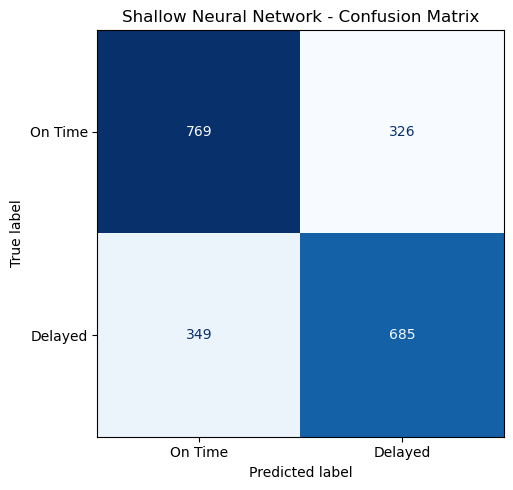

In [80]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_congestion_test, y_final_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["On Time", "Delayed"]
)

fig, ax = plt.subplots(figsize=(6, 5))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Shallow Neural Network - Confusion Matrix")

plt.tight_layout()
plt.savefig("nn_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


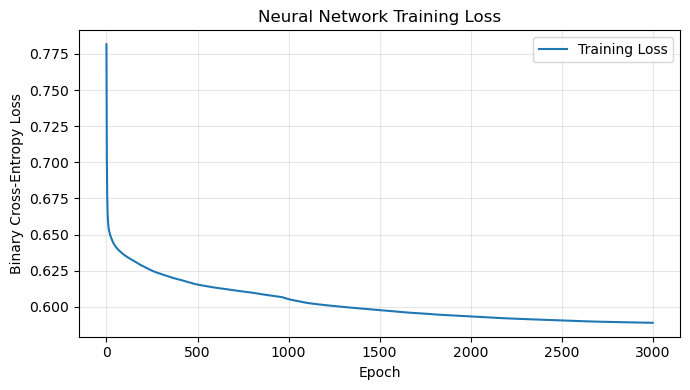

In [81]:

plt.figure(figsize=(7, 4))

plt.plot(final_losses, label="Training Loss")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Neural Network Training Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("nn_training_loss.png", dpi=300, bbox_inches="tight")
plt.show()


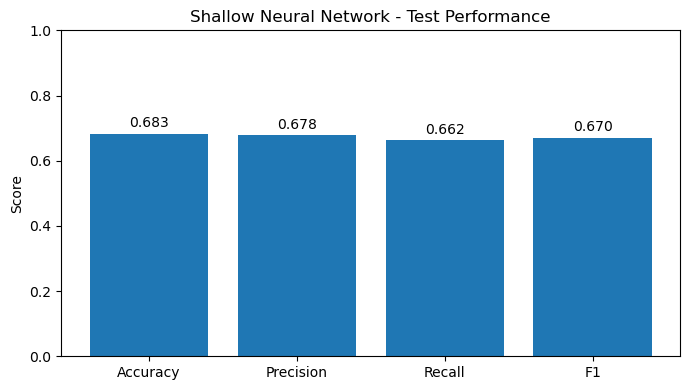

In [82]:

metrics = {
    "Accuracy": final_accuracy,
    "Precision": final_precision,
    "Recall": final_recall,
    "F1": final_f1
}

plt.figure(figsize=(7, 4))

bars = plt.bar(metrics.keys(), metrics.values())

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Shallow Neural Network - Test Performance")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig("nn_test_metrics.png", dpi=300, bbox_inches="tight")
plt.show()
